In [31]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.draw import disk

# GLOBAL VARIABLES
Nx = 520
Ny = 180
Ly = Ny-1
CylinderCenter = (Nx/4, Ny/2)
CylinderRadius = Ny/9
U_lb = 0.04 # velocity in latice units
Re = 220 # Reynolds Number
V_lb = (U_lb * CylinderRadius) / Re
Tau = 3 * V_lb + 0.5 # relaxation time

THE PROGRAM LOOPS BACK TO FRONT -- fix!!!

(520, 180, 9)


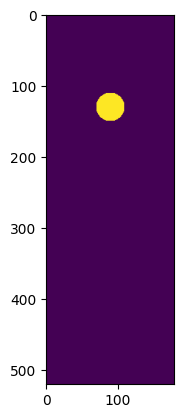

In [32]:
# lattice description
matrix = np.zeros((Nx,Ny, 9))
print(matrix.shape)

# obstruction description
# NOTE change this to take a png as an input for extra points
obstacle_mask = np.zeros((Nx,Ny), dtype=np.bool)
rr, cc = disk(CylinderCenter, CylinderRadius, shape=obstacle_mask.shape)
obstacle_mask[rr, cc] = True
plt.imshow(obstacle_mask)

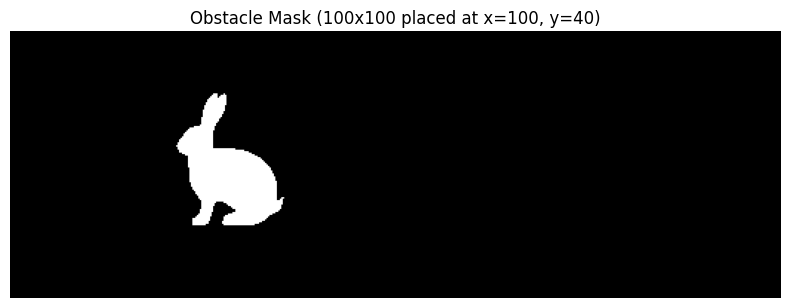

In [33]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the obstacle's target size and position in the lattice
obs_width = 100   # How wide the image should be in pixels
obs_height = 100  # How tall the image should be in pixels
offset_x = 100    # X coordinate for the top-left corner of the image
offset_y = 40     # Y coordinate for the top-left corner of the image

# 2. Create an empty (all False) mask for the entire simulation domain
obstacle_mask = np.zeros((Nx, Ny), dtype=bool)

# 3. Read image, convert to grayscale, and resize strictly to (obs_width, obs_height)
img = Image.open("rbbt.png").convert("L").resize((obs_width, obs_height))

# 4. Convert to numpy array, transpose to match (X, Y) math, and threshold
sub_mask = np.array(img).T < 25

# 5. Insert the sub_mask into the main obstacle_mask
# We calculate boundaries to ensure it doesn't crash if placed near the edge
end_x = min(offset_x + obs_width, Nx)
end_y = min(offset_y + obs_height, Ny)
fit_w = end_x - offset_x
fit_h = end_y - offset_y

obstacle_mask[offset_x:end_x, offset_y:end_y] = sub_mask[:fit_w, :fit_h]

# Optional: Visualize to confirm
plt.figure(figsize=(10, 10 * (Ny/Nx)))
plt.imshow(obstacle_mask.T, cmap='gray')
plt.title(f"Obstacle Mask ({obs_width}x{obs_height} placed at x={offset_x}, y={offset_y})")
plt.axis('off')
plt.show()

In [34]:
# inlet flow
def u_inlet_x(y):
    """
    Intlet flow with a small introduced perturbation.
    """
    return U_lb * (1.0 + 1e-2*np.sin(y/(2*np.pi*(Ny-1))))

# velocity vector
velVectors = np.array([(x,y) for x in [0,-1,1] for y in [0,-1,1]])
Weights = np.array((4/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/9, 1/36, 1/36))
print(Weights)

def calc_ro(matrix):
    """
    Sum all distribution functions (directions) for each lattice cell.
    Formula: rho = sum(f_i)
    """
    # matrix shape is (Nx, Ny, 9), we sum over the last axis
    return np.sum(matrix, axis=2)

def calc_u(matrix, c):
    """
    Calculate the macroscopic velocity vector for each pixel.
    Formula: u = (1/rho) * sum(f_i * c_i)
    """
    rho = calc_ro(matrix)
    # Compute momentum: sum of (f_i * c_i) for each cell
    # np.tensordot multiplies the 9 directions in 'matrix' by the vectors in 'c'
    momentum = np.tensordot(matrix, c, axes=(2, 0)) # Result shape: (Nx, Ny, 2)
    
    # Divide momentum by density to get velocity
    # We add np.newaxis to rho to broadcast (Nx, Ny) over the 2 velocity components
    return momentum / rho[..., np.newaxis]

def calc_feq(rho, u, c, weights):
    """
    Calculates the Equilibrium distribution for all 9 directions.
    Formula: feq_i = W_i * rho * [1 + 3(c_i.u) + 4.5(c_i.u)^2 - 1.5u^2]
    """
    # Calculate u^2 (dot product of velocity with itself)
    u_sq = np.sum(u**2, axis=2) # Result shape: (Nx, Ny)
    
    # Calculate dot product (c_i . u) for all 9 directions i
    # Result shape: (Nx, Ny, 9)[cite: 1]
    dot_product = np.tensordot(u, c, axes=(2, 1))
    
    # Apply the equilibrium formula[cite: 1]
    # We use broadcasting for weights (9,) and rho (Nx, Ny)
    term1 = 3.0 * dot_product
    term2 = 4.5 * (dot_product**2)
    term3 = 1.5 * u_sq[..., np.newaxis]
    
    feq = weights[np.newaxis, np.newaxis, :] * rho[..., np.newaxis] * (1.0 + term1 + term2 - term3)
    return feq


[0.44444444 0.11111111 0.11111111 0.11111111 0.02777778 0.02777778
 0.11111111 0.02777778 0.02777778]


In [35]:
from IPython.display import display, Image
import matplotlib.pyplot as plt
import io
import imageio.v2 as imageio

# Initialisation
vel = np.fromfunction(lambda d,x,y: (1-d) * U_lb * (1.0 + 1e-4 * np.sin(y/(Ly) * 2 * np.pi)), (2, Nx, Ny))
vel = np.transpose(vel, (1, 2, 0))

# rho = 1.0
rho_initial = np.ones((Nx, Ny))

# initial pop
fin = calc_feq(rho_initial, vel, velVectors, Weights)

noslip = [0, 2, 1, 6, 8, 7, 3, 5, 4]

frames = []

for time_step in range(30000):
    # Right boundary condition -- fluid moving out
    fin[-1, :, :] = fin[-2, :, :]

    rho = calc_ro(fin)
    u = calc_u(fin, velVectors)

    # Left Boundary
    u[0, :, 0] = u_inlet_x(np.arange(Ny)) # V_x
    u[0, :, 1] = 0.0 # V_y
    rho[0, :] = 1.0

    # Colision step
    feq = calc_feq(rho, u, velVectors, Weights)
    fout = fin - (fin - feq) / Tau

    # No slip on obstacle
    for i in range(9):
        fout[obstacle_mask, i] = fin[obstacle_mask, noslip[i]]

    # Streaming
    for i in range(9):
        fin[:, :, i] = np.roll(
            np.roll(fout[:, :, i], velVectors[i, 0], axis=0),
            velVectors[i, 1], axis=1
        )
    
    # Visualisation:
    if time_step % 100 == 0:
        vel_magnitude = np.sqrt(u[:, :, 0]**2 + u[:, :, 1]**2)
        vel_magnitude[obstacle_mask] = 0 
        
        fig, ax = plt.subplots(figsize=(10, 4))
        
        cax = ax.imshow(vel_magnitude.T, cmap='GnBu')
        
        buf = io.BytesIO()
        
        plt.savefig(buf, format='png') 
        plt.close(fig) 
        
        # Read the buffer into an imageio format and append to frames
        buf.seek(0)
        frames.append(imageio.imread(buf))
        
        print(f"Processed {time_step} steps...")

# Save the compiled frames as a GIF
gif_path = "von_karman_rbbt.gif"
imageio.mimsave(gif_path, frames, fps=15, loop=0) # Adjust fps to speed up/slow down the gif
print(f"GIF -- {gif_path}")


Processed 0 steps...
Processed 100 steps...
Processed 200 steps...
Processed 300 steps...
Processed 400 steps...
Processed 500 steps...
Processed 600 steps...
Processed 700 steps...
Processed 800 steps...
Processed 900 steps...
Processed 1000 steps...
Processed 1100 steps...
Processed 1200 steps...
Processed 1300 steps...
Processed 1400 steps...
Processed 1500 steps...
Processed 1600 steps...
Processed 1700 steps...
Processed 1800 steps...
Processed 1900 steps...
Processed 2000 steps...
Processed 2100 steps...
Processed 2200 steps...
Processed 2300 steps...
Processed 2400 steps...
Processed 2500 steps...
Processed 2600 steps...
Processed 2700 steps...
Processed 2800 steps...
Processed 2900 steps...
Processed 3000 steps...
Processed 3100 steps...
Processed 3200 steps...
Processed 3300 steps...
Processed 3400 steps...
Processed 3500 steps...
Processed 3600 steps...
Processed 3700 steps...
Processed 3800 steps...
Processed 3900 steps...
Processed 4000 steps...
Processed 4100 steps...
Proc